# 第8回：モンテカルロ法1

[講義スライド](slide.pdf) ｜ [2026年度の資料一覧](../README.md)

GitHubから Google Colab で開いた後、**「ドライブにコピーを保存」**してください。

## 一様乱数で積分する

区間 $[a,b]$ の一様分布に従う確率変数 $X$ に対して、

$$
\int_a^b f(x)\,dx=(b-a)\,\mathbb{E}[f(X)]
$$

です。乱数 $x_1,\ldots,x_N$ の平均で期待値を近似します。

$$
I_N=\frac{b-a}{N}\sum_{i=1}^N f(x_i),\qquad x_i\sim\operatorname{Uniform}(a,b).
$$

以下では $\int_0^\pi\sin x\,dx=2$ を例に、誤差の変化を見ます。

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(2026)
N_max = 1_000_000
x = rng.uniform(0.0, np.pi, size=N_max)
samples = np.pi * np.sin(x)
cumulative = np.cumsum(samples)
N_values = np.array([100, 1_000, 10_000, 100_000, 1_000_000])
estimates = cumulative[N_values - 1] / N_values
exact_integral = 2.0
variance = np.pi**2 / 2 - exact_integral**2
standard_errors = np.sqrt(variance / N_values)

for n, estimate, se in zip(N_values, estimates, standard_errors):
    print(f"N={n:>7}: I_N={estimate:.6f}, 1σ={se:.6f}")

N=    100: I_N=2.210170, 1σ=0.096685
N=   1000: I_N=2.020506, 1σ=0.030575
N=  10000: I_N=2.003000, 1σ=0.009669
N= 100000: I_N=1.998336, 1σ=0.003057
N=1000000: I_N=1.999590, 1σ=0.000967


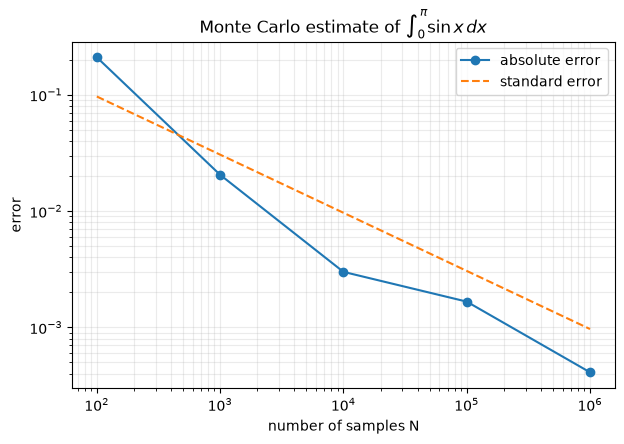

In [2]:
plt.figure(figsize=(7, 4.5))
plt.loglog(N_values, np.abs(estimates - exact_integral), "o-", label="absolute error")
plt.loglog(N_values, standard_errors, "--", label="standard error")
plt.xlabel("number of samples N")
plt.ylabel("error")
plt.title(r"Monte Carlo estimate of $\int_0^\pi \sin x\,dx$")
plt.grid(True, which="both", alpha=0.25)
plt.legend()
plt.show()

In [3]:
# The fixed seed makes this numerical check reproducible.
assert abs(estimates[-1] - exact_integral) < 5 * standard_errors[-1]
print("Exact value:", exact_integral)
print("Estimate at N=1,000,000:", estimates[-1])

Exact value: 2.0
Estimate at N=1,000,000: 1.9995896230939856


## 円の面積から $\pi$ を見積もる

正方形 $[0,1]\times[0,1]$ に一様に点を取り、$x^2+y^2\leq1$ を満たす割合を数えます。単位円の4分の1の面積は $\pi/4$ です。

$$
\widehat{\pi}=4\frac{K}{N},
$$

ここで $K$ は円内に入った点の数です。

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


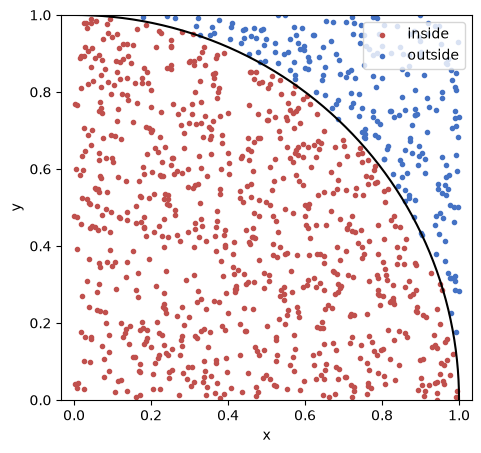

In [4]:
N_plot = 1_000
points = rng.random((N_plot, 2))
inside = np.sum(points**2, axis=1) <= 1.0

angle = np.linspace(0, np.pi / 2, 300)
plt.figure(figsize=(5.3, 5.0))
plt.plot(np.cos(angle), np.sin(angle), color="black")
plt.scatter(points[inside, 0], points[inside, 1], s=9, color="#C0504D", label="inside")
plt.scatter(points[~inside, 0], points[~inside, 1], s=9, color="#4472C4", label="outside")
plt.xlabel("x")
plt.ylabel("y")
plt.axis("equal")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend()
plt.show()

In [5]:
N_pi = 500_000
points = rng.random((N_pi, 2))
inside_count = np.count_nonzero(np.sum(points**2, axis=1) <= 1.0)
pi_estimate = 4 * inside_count / N_pi
pi_standard_error = 4 * np.sqrt((np.pi / 4) * (1 - np.pi / 4) / N_pi)
print("estimate of pi:", pi_estimate)
print("one standard error:", pi_standard_error)
assert abs(pi_estimate - np.pi) < 5 * pi_standard_error

estimate of pi: 3.140728
one standard error: 0.002322397990556233


## なぜモンテカルロ法を使うのか

各軸を $n$ 分割する格子法では、$d$ 次元で点数が $n^d$ 個になります。次元とともに計算量が急増するため、「次元の呪い」と呼ばれます。

モンテカルロ標本平均の標準誤差は、有限な分散のもとで $O(N^{-1/2})$ です。この収束次数は次元に直接依存しません。ただし、次元や関数によって分散が大きくなり、実用上の誤差が増えることはあります。

## 分布に合わせて標本を取る

関数が狭い領域で大きな値を取ると、一様乱数ではその領域をほとんど訪れず、効率が下がることがあります。積分を

$$
\int f(x)\,dx=\int \frac{f(x)}{p(x)}p(x)\,dx
$$

と書き換える重要度サンプリングでは、$f(x)\ne0$となる領域で$p(x)>0$であることが必要です。重要な領域で大きい確率密度$p(x)$を使うと効率が上がる場合があります。必要な分布からの標本生成が難しい場合に、マルコフ連鎖モンテカルロ（MCMC）を使います。

## マルコフ連鎖モンテカルロ

目標分布 $P(x)$ に従う標本列 $x_1,x_2,\ldots$ を作り、十分長い履歴の頻度から分布を近似します。連鎖の更新で用いる確率は直前の状態だけに依存します（マルコフ性）。

定常分布へ収束させるため、既約性・非周期性・詳細つり合いなどの条件を確認します。詳細つり合いは

$$
P(x)T(x\to x')=P(x')T(x'\to x)
$$

です。遷移確率の流入と流出が釣り合い、$P$を定常分布にします。

## メトロポリス法

目標分布が $P(x)\propto e^{-S(x)}$ と書けるとします。

1. 現在の $x$ から候補 $x'$ を提案します。
2. $\min\{1,e^{S(x)-S(x')}\}$ の確率で候補を採択します。
3. 採択なら $x\leftarrow x'$、棄却なら現在の値に留まります。

提案分布が対称なら、この採択規則は詳細つり合いを満たします。

In [6]:
def action(x):
    return 0.5 * x**2

def metropolis(steps, x_initial, rng):
    x = float(x_initial)
    chain = np.empty(steps + 1)
    chain[0] = x
    accepted = 0
    for i in range(steps):
        proposal = x + rng.uniform(-1.0, 1.0)
        acceptance = min(1.0, np.exp(action(x) - action(proposal)))
        if rng.random() < acceptance:
            x = proposal
            accepted += 1
        chain[i + 1] = x
    return chain, accepted / steps

chain, acceptance_rate = metropolis(50_000, 0.0, rng)
print("acceptance rate:", acceptance_rate)

acceptance rate: 0.80352


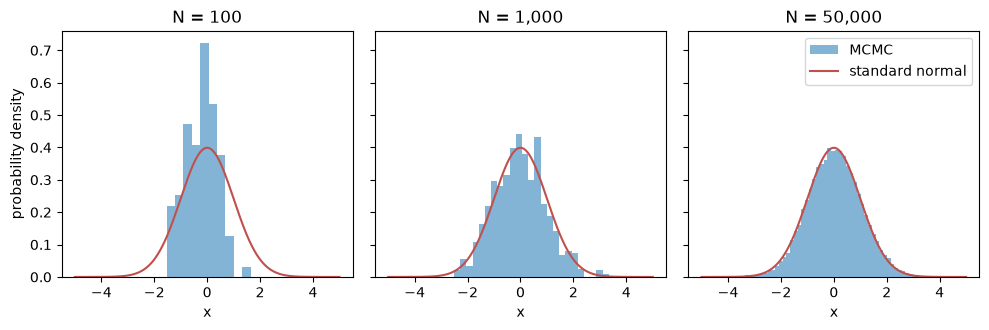

In [7]:
x_grid = np.linspace(-5, 5, 500)
normal_density = np.exp(-0.5 * x_grid**2) / np.sqrt(2 * np.pi)

fig, axes = plt.subplots(1, 3, figsize=(10, 3.4), sharey=True)
for ax, n, bins in zip(axes, [100, 1_000, 50_000], [10, 25, 60]):
    ax.hist(chain[1:n + 1], bins=bins, density=True, alpha=0.55, label="MCMC")
    ax.plot(x_grid, normal_density, color="#C0504D", label="standard normal")
    ax.set_title(f"N = {n:,}")
    ax.set_xlabel("x")
axes[0].set_ylabel("probability density")
axes[-1].legend()
fig.tight_layout()
plt.show()

## 演習：$d$ 次元単位球の体積

一辺が2の立方体 $[-1,1]^d$ から一様に点を取り、単位球に入る割合から体積を求めます。解析解は

$$
V_d=\frac{\pi^{d/2}}{\Gamma(d/2+1)}.
$$

`math.gamma`でガンマ関数を計算し、$d=2,4,8$などでモンテカルロ推定と比較してください。

In [ ]:
# ここに演習のコードを書く


## 演習：二峰性分布

次の作用に対応する確率分布を、メトロポリス法で再現してください。

$$
S(x)=-\log\left(e^{-\frac12(x-3)^2}+e^{-\frac12(x+3)^2}\right).
$$

二つの山を両方訪れるか、初期値や提案幅を変えて調べます。

In [ ]:
# ここに演習のコードを書く


## 発展：疑似乱数について調べる

乱数シード、周期、統計的検定が数値シミュレーションに与える影響を調べ、短くまとめてください。